# Partie 6 — Analyse du comportement temporel (Temporal Behaviour Analysis)

Cette partie étudie le **comportement temporel** des variables industrielles du dataset **HAI 23.05**.

**Objectifs :**
- Analyser la stabilité et la variabilité des signaux (Rolling Mean / Std)
- Étudier les dépendances temporelles (ACF)
- Examiner les relations décalées entre capteurs (Lag Analysis)
- Détecter les ruptures de comportement (Change Point Detection)
- Comparer le comportement des capteurs **avant, pendant et après** les attaques

L’analyse se concentre principalement sur les fichiers de test (`hai-test1` et `hai-test2`), qui contiennent les périodes d’attaque.

In [4]:
!pip install statsmodels ruptures

   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
    --------------------------------------- 0.3/11.4 MB ? eta -:--:--
    --------------------------------------- 0.3/11.4 MB ? eta -:--:--
    --------------------------------------- 0.3/11.4 MB ? eta -:--:--
    --------------------------------------- 0.3/11.4 MB ? eta -:--:--
    --------------------------------------- 0.3/11.4 MB ? eta -:--:--
    --------------------------------------- 0.3/11.4 MB ? eta -:--:--
    --------------------------------------- 0.3/11.4 MB ? eta -:--:--
   - ---------------

In [11]:
from pathlib import Path
import json, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.patches import Patch
from scipy import stats
warnings.filterwarnings("ignore")

DATA_DIR = Path(
    r"C:\Users\LENOVO\OneDrive - Ministere de l'Enseignement Superieur et de la Recherche Scientifique\Bureau\mlops\data\raw\hai-23.05"
)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dossier introuvable : {DATA_DIR}")

print("Dossier des données :", DATA_DIR)

Dossier des données : C:\Users\LENOVO\OneDrive - Ministere de l'Enseignement Superieur et de la Recherche Scientifique\Bureau\mlops\data\raw\hai-23.05


In [12]:
from pathlib import Path

DATA_ROOT = Path(
    r"C:\Users\LENOVO\OneDrive - Ministere de l'Enseignement Superieur et de la Recherche Scientifique\Bureau\mlops\data\raw\hai-23.05"
)

VERSION_TAG = "23.05"
STRICT_OFFICIAL_CHECKS = True

assert DATA_ROOT.exists(), f"Dossier introuvable : {DATA_ROOT}"

print("DATA_ROOT :", DATA_ROOT)
print("VERSION_TAG :", VERSION_TAG)

DATA_ROOT : C:\Users\LENOVO\OneDrive - Ministere de l'Enseignement Superieur et de la Recherche Scientifique\Bureau\mlops\data\raw\hai-23.05
VERSION_TAG : 23.05


In [16]:
# Chargement des données industrielles
train_files = [
    "hai-train1",
    "hai-train2",
    "hai-train3"
]

test_files = [
    "hai-test1",
    "hai-test2"
]

df_train = pd.concat(
    [pd.read_csv(FILES[f]) for f in train_files],
    ignore_index=True
)

df_test = pd.concat(
    [pd.read_csv(FILES[f]) for f in test_files],
    ignore_index=True
)

# Chargement des labels
df_labels = pd.concat(
    [
        pd.read_csv(FILES["label-test1"]),
        pd.read_csv(FILES["label-test2"])
    ],
    ignore_index=True
)

print("Train :", df_train.shape)
print("Test :", df_test.shape)
print("Labels :", df_labels.shape)

Train : (698400, 87)
Test : (284400, 87)
Labels : (284400, 2)


In [17]:
# Afficher tous les fichiers CSV disponibles
for path in sorted(DATA_ROOT.rglob("*.csv")):
    print(path.name, " | ", path.stat().st_size, "octets")

hai-test1.csv  |  31255559 octets
hai-test2.csv  |  132946575 octets
hai-train1.csv  |  162418984 octets
hai-train2.csv  |  169121615 octets
hai-train3.csv  |  72774793 octets
hai-train4.csv  |  114494940 octets
label-test1.csv  |  1242017 octets
label-test2.csv  |  4500018 octets


In [18]:
for name in train_files:
    temp = pd.read_csv(FILES[name])
    print(name, temp.shape)

hai-train1 (280800, 87)
hai-train2 (291600, 87)
hai-train3 (126000, 87)


In [20]:
FILES["hai-train4"] = DATA_ROOT / "hai-train4.csv"

df_train4 = pd.read_csv(FILES["hai-train4"])

print("hai-train4 :", df_train4.shape)

hai-train4 : (198000, 87)


In [21]:
train_files = [
    "hai-train1",
    "hai-train2",
    "hai-train3",
    "hai-train4"
]

df_train = pd.concat(
    [pd.read_csv(FILES[f]) for f in train_files],
    ignore_index=True
)

print("Train complet :", df_train.shape)

Train complet : (896400, 87)


Préparation des données temporelles

In [22]:
# Afficher les colonnes
print("Colonnes du train :")
print(df_train.columns.tolist())

print("\nColonnes du test :")
print(df_test.columns.tolist())

print("\nColonnes des labels :")
print(df_labels.columns.tolist())

Colonnes du train :
['timestamp', 'P1_FCV01D', 'P1_FCV01Z', 'P1_FCV02D', 'P1_FCV02Z', 'P1_FCV03D', 'P1_FCV03Z', 'P1_FT01', 'P1_FT01Z', 'P1_FT02', 'P1_FT02Z', 'P1_FT03', 'P1_FT03Z', 'P1_LCV01D', 'P1_LCV01Z', 'P1_LIT01', 'P1_PCV01D', 'P1_PCV01Z', 'P1_PCV02D', 'P1_PCV02Z', 'P1_PIT01', 'P1_PIT01_HH', 'P1_PIT02', 'P1_PP01AD', 'P1_PP01AR', 'P1_PP01BD', 'P1_PP01BR', 'P1_PP02D', 'P1_PP02R', 'P1_PP04', 'P1_PP04D', 'P1_PP04SP', 'P1_SOL01D', 'P1_SOL03D', 'P1_STSP', 'P1_TIT01', 'P1_TIT02', 'P1_TIT03', 'P2_24Vdc', 'P2_ATSW_Lamp', 'P2_AutoGO', 'P2_AutoSD', 'P2_Emerg', 'P2_MASW', 'P2_MASW_Lamp', 'P2_ManualGO', 'P2_ManualSD', 'P2_OnOff', 'P2_RTR', 'P2_SCO', 'P2_SCST', 'P2_SIT01', 'P2_TripEx', 'P2_VIBTR01', 'P2_VIBTR02', 'P2_VIBTR03', 'P2_VIBTR04', 'P2_VT01', 'P2_VTR01', 'P2_VTR02', 'P2_VTR03', 'P2_VTR04', 'P3_FIT01', 'P3_LCP01D', 'P3_LCV01D', 'P3_LH01', 'P3_LIT01', 'P3_LL01', 'P3_PIT01', 'P4_HT_FD', 'P4_HT_PO', 'P4_HT_PS', 'P4_LD', 'P4_ST_FD', 'P4_ST_GOV', 'P4_ST_LD', 'P4_ST_PO', 'P4_ST_PS', 'P4_ST_PT

Préparation des données

In [23]:
# Identifier les variables industrielles
sensor_cols = [
    c for c in df_train.columns
    if c != "timestamp"
]

# Vérifier la correspondance des dimensions
assert len(df_test) == len(df_labels), \
    "Les dimensions du test et des labels sont différentes."

# Préparer le test avec ses labels
df_test_labeled = df_test.copy()

df_test_labeled["label"] = pd.to_numeric(
    df_labels["label"],
    errors="raise"
).to_numpy()

# Conversion des timestamps
df_train["timestamp"] = pd.to_datetime(
    df_train["timestamp"], errors="coerce"
)

df_test_labeled["timestamp"] = pd.to_datetime(
    df_test_labeled["timestamp"], errors="coerce"
)

print("Nombre de capteurs :", len(sensor_cols))
print("Train :", df_train.shape)
print("Test :", df_test_labeled.shape)

print("\nDistribution des labels :")
print(df_test_labeled["label"].value_counts())

Nombre de capteurs : 86
Train : (896400, 87)
Test : (284400, 88)

Distribution des labels :
label
0    273016
1     11384
Name: count, dtype: int64


Vérification de la continuité temporelle

In [24]:
# Vérification temporelle du train et du test
for name, df in {
    "Train": df_train,
    "Test": df_test_labeled
}.items():

    df_sorted = df.sort_values("timestamp")

    intervals = df_sorted["timestamp"].diff().dt.total_seconds()

    print(f"\n===== {name} =====")
    print("Timestamps invalides :", df["timestamp"].isna().sum())
    print("Ordre chronologique :", df["timestamp"].is_monotonic_increasing)
    print("\nIntervalles entre observations (secondes) :")
    print(intervals.value_counts().head(10))
    print("Intervalle médian :", intervals.median())


===== Train =====
Timestamps invalides : 0
Ordre chronologique : True

Intervalles entre observations (secondes) :
timestamp
1.0         896396
457201.0         1
259201.0         1
136801.0         1
Name: count, dtype: int64
Intervalle médian : 1.0

===== Test =====
Timestamps invalides : 0
Ordre chronologique : True

Intervalles entre observations (secondes) :
timestamp
1.0         284398
320401.0         1
Name: count, dtype: int64
Intervalle médian : 1.0


Interprétation
- Les timestamps sont tous valides.
- Les données sont chronologiquement ordonnées.
- L'intervalle médian est de 1 seconde pour Train et Test.
- Les grands intervalles (136 801 s, 259 201 s, etc.) correspondent probablement aux transitions entre les fichiers concaténés.

Vérification temporelle fichier par fichier

In [25]:
for name, path in FILES.items():

    if "train" not in name and "test" not in name:
        continue

    temp = pd.read_csv(path, usecols=["timestamp"])
    temp["timestamp"] = pd.to_datetime(temp["timestamp"])

    print(f"\n===== {name} =====")
    print("Début :", temp["timestamp"].min())
    print("Fin   :", temp["timestamp"].max())
    print("Nombre de lignes :", len(temp))


===== hai-train1 =====
Début : 2022-08-04 18:00:01
Fin   : 2022-08-08 00:00:00
Nombre de lignes : 280800

===== hai-train2 =====
Début : 2022-08-13 07:00:01
Fin   : 2022-08-16 16:00:00
Nombre de lignes : 291600

===== hai-train3 =====
Début : 2022-08-19 16:00:01
Fin   : 2022-08-21 03:00:00
Nombre de lignes : 126000

===== hai-test1 =====
Début : 2022-08-12 16:00:01
Fin   : 2022-08-13 07:00:00
Nombre de lignes : 54000

===== hai-test2 =====
Début : 2022-08-17 00:00:01
Fin   : 2022-08-19 16:00:00
Nombre de lignes : 230400

===== label-test1 =====
Début : 2022-08-12 16:00:01
Fin   : 2022-08-13 07:00:00
Nombre de lignes : 54000

===== label-test2 =====
Début : 2022-08-17 00:00:00
Fin   : 2022-08-19 16:00:00
Nombre de lignes : 230400

===== hai-train4 =====
Début : 2022-08-22 17:00:01
Fin   : 2022-08-25 00:00:00
Nombre de lignes : 198000


Les quatre fichiers Train couvrent des périodes différentes.



Les deux fichiers Test couvrent également des périodes distinctes.



Chaque fichier possède une fréquence d'échantillonnage d'une seconde.



Les grands intervalles observés précédemment correspondent aux interruptions entre les fichiers, et non à des observations manquantes à chaque seconde.

Préparation des séries temporelles

In [26]:
# Préparer les séries temporelles par fichier

SEGMENTS = {}

for name in [
    "hai-train1", "hai-train2",
    "hai-train3", "hai-train4",
    "hai-test1", "hai-test2"
]:
    temp = pd.read_csv(FILES[name])
    temp["timestamp"] = pd.to_datetime(temp["timestamp"])

    if "test" in name:
        SEGMENTS[name] = temp.copy()

    else:
        SEGMENTS[name] = temp.copy()

    SEGMENTS[name] = SEGMENTS[name].sort_values(
        "timestamp"
    ).reset_index(drop=True)

# Ajouter les labels aux fichiers Test
n1 = len(SEGMENTS["hai-test1"])

SEGMENTS["hai-test1"]["label"] = (
    df_labels.iloc[:n1]["label"].to_numpy()
)

SEGMENTS["hai-test2"]["label"] = (
    df_labels.iloc[n1:]["label"].to_numpy()
)

# Vérification
for name, df in SEGMENTS.items():
    print(
        name,
        "| Lignes :", len(df),
        "| Début :", df["timestamp"].min(),
        "| Fin :", df["timestamp"].max()
    )

hai-train1 | Lignes : 280800 | Début : 2022-08-04 18:00:01 | Fin : 2022-08-08 00:00:00
hai-train2 | Lignes : 291600 | Début : 2022-08-13 07:00:01 | Fin : 2022-08-16 16:00:00
hai-train3 | Lignes : 126000 | Début : 2022-08-19 16:00:01 | Fin : 2022-08-21 03:00:00
hai-train4 | Lignes : 198000 | Début : 2022-08-22 17:00:01 | Fin : 2022-08-25 00:00:00
hai-test1 | Lignes : 54000 | Début : 2022-08-12 16:00:01 | Fin : 2022-08-13 07:00:00
hai-test2 | Lignes : 230400 | Début : 2022-08-17 00:00:01 | Fin : 2022-08-19 16:00:00


Évolution temporelle des capteurs
Objectif
Observer l'évolution des variables industrielles et identifier les variations de comportement pendant les attaques.

In [ ]:
# Afficher les colonnes
print("Colonnes du train :")
print(df_train.columns.tolist())

print("\nColonnes du test :")
print(df_test.columns.tolist())

print("\nColonnes des labels :")
print(df_labels.columns.tolist())

Colonnes du train :
['timestamp', 'P1_FCV01D', 'P1_FCV01Z', 'P1_FCV02D', 'P1_FCV02Z', 'P1_FCV03D', 'P1_FCV03Z', 'P1_FT01', 'P1_FT01Z', 'P1_FT02', 'P1_FT02Z', 'P1_FT03', 'P1_FT03Z', 'P1_LCV01D', 'P1_LCV01Z', 'P1_LIT01', 'P1_PCV01D', 'P1_PCV01Z', 'P1_PCV02D', 'P1_PCV02Z', 'P1_PIT01', 'P1_PIT01_HH', 'P1_PIT02', 'P1_PP01AD', 'P1_PP01AR', 'P1_PP01BD', 'P1_PP01BR', 'P1_PP02D', 'P1_PP02R', 'P1_PP04', 'P1_PP04D', 'P1_PP04SP', 'P1_SOL01D', 'P1_SOL03D', 'P1_STSP', 'P1_TIT01', 'P1_TIT02', 'P1_TIT03', 'P2_24Vdc', 'P2_ATSW_Lamp', 'P2_AutoGO', 'P2_AutoSD', 'P2_Emerg', 'P2_MASW', 'P2_MASW_Lamp', 'P2_ManualGO', 'P2_ManualSD', 'P2_OnOff', 'P2_RTR', 'P2_SCO', 'P2_SCST', 'P2_SIT01', 'P2_TripEx', 'P2_VIBTR01', 'P2_VIBTR02', 'P2_VIBTR03', 'P2_VIBTR04', 'P2_VT01', 'P2_VTR01', 'P2_VTR02', 'P2_VTR03', 'P2_VTR04', 'P3_FIT01', 'P3_LCP01D', 'P3_LCV01D', 'P3_LH01', 'P3_LIT01', 'P3_LL01', 'P3_PIT01', 'P4_HT_FD', 'P4_HT_PO', 'P4_HT_PS', 'P4_LD', 'P4_ST_FD', 'P4_ST_GOV', 'P4_ST_LD', 'P4_ST_PO', 'P4_ST_PS', 'P4_ST_PT

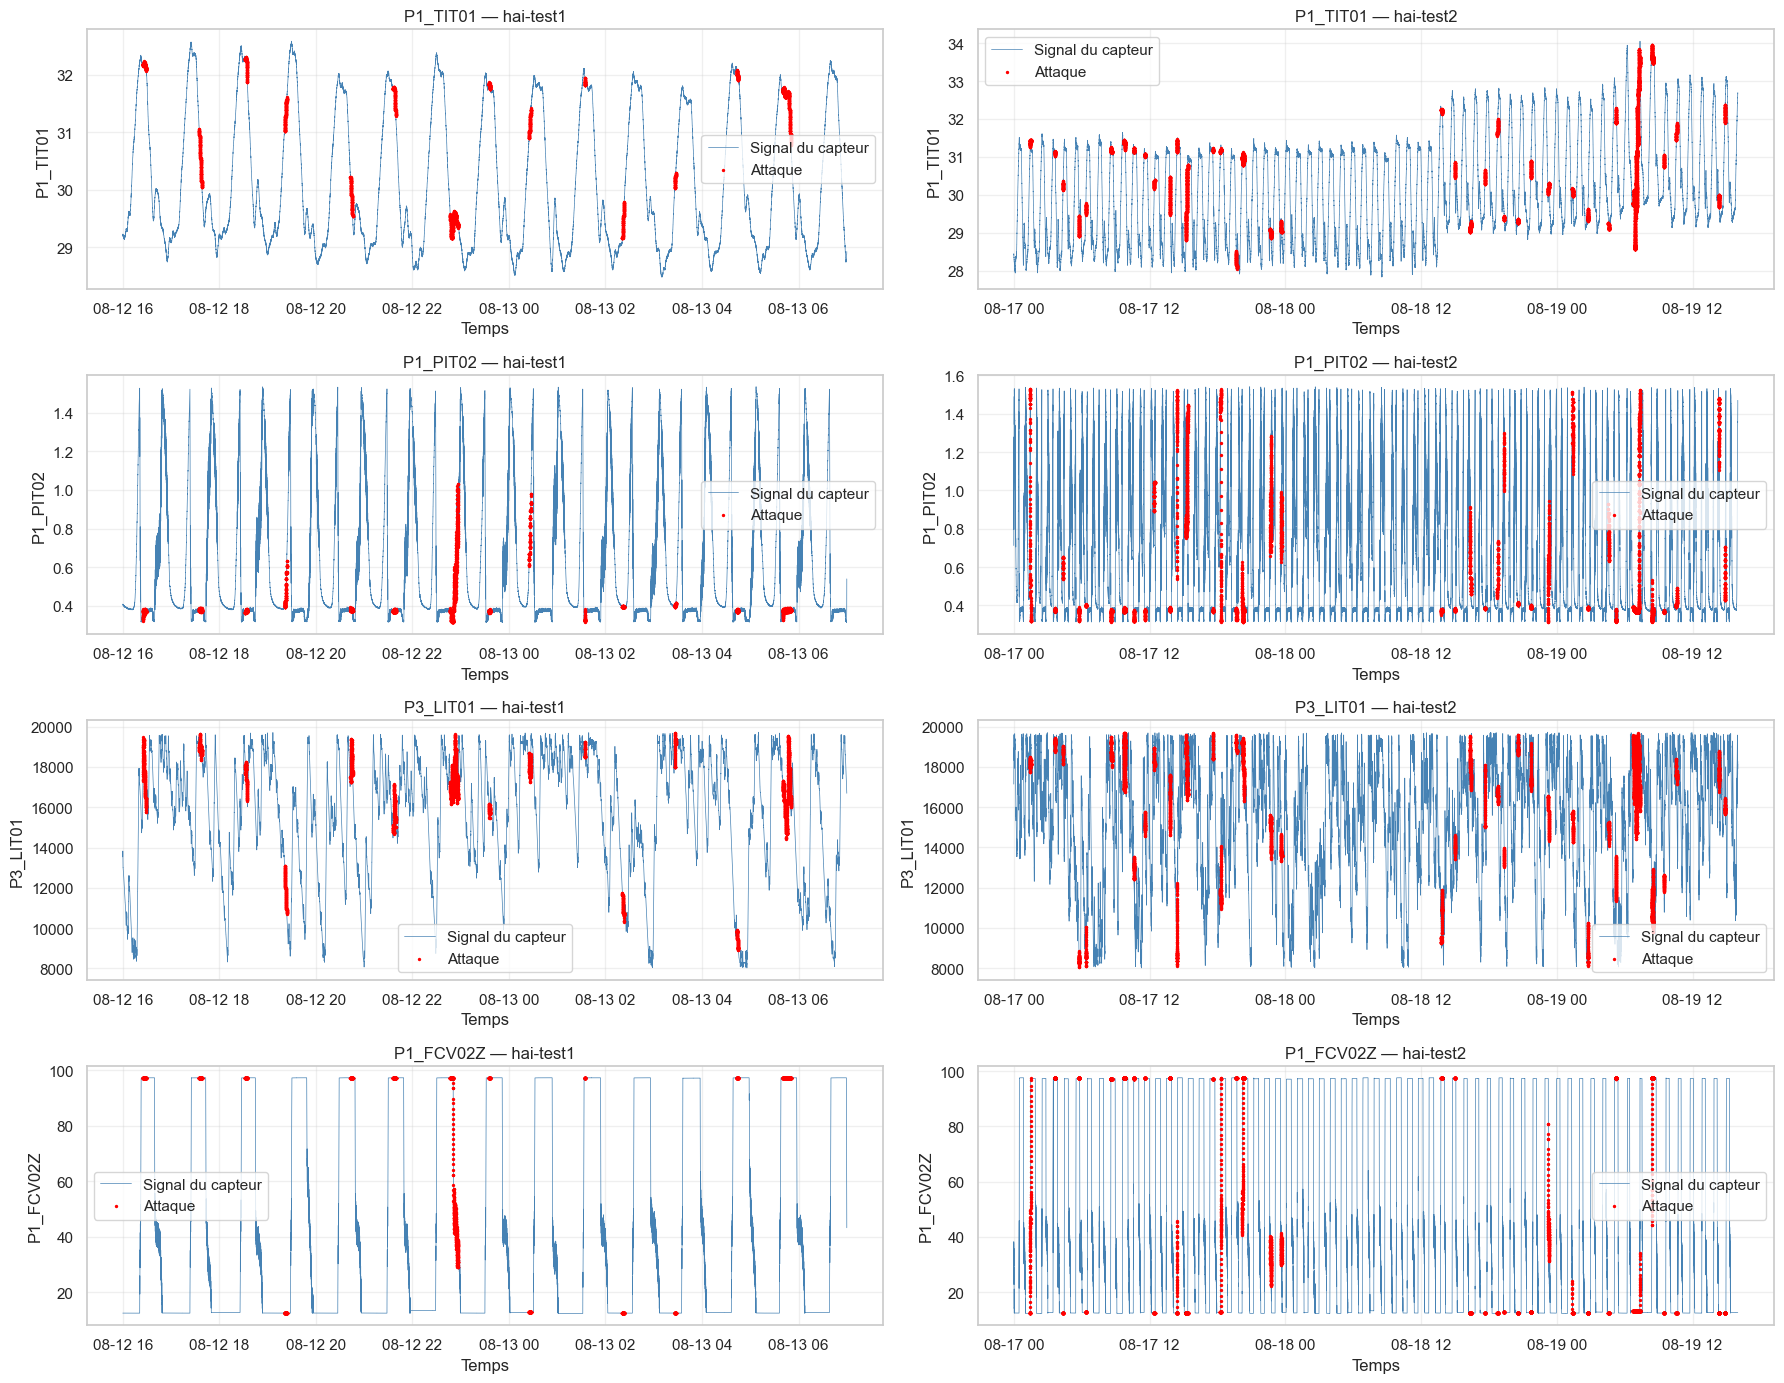

In [27]:
# Sélection des capteurs représentatifs
SELECTED_SENSORS = [
    "P1_TIT01",
    "P1_PIT02",
    "P3_LIT01",
    "P1_FCV02Z"
]

# Vérification
assert all(c in df_train.columns for c in SELECTED_SENSORS)

# Visualisation des périodes de test
fig, axes = plt.subplots(
    4, 2, figsize=(18, 14)
)

for i, sensor in enumerate(SELECTED_SENSORS):

    for j, segment in enumerate(["hai-test1", "hai-test2"]):

        data = SEGMENTS[segment]
        ax = axes[i, j]

        ax.plot(
            data["timestamp"],
            data[sensor],
            linewidth=0.5,
            color="steelblue",
            label="Signal du capteur"
        )

        attacks = data[data["label"] == 1]

        ax.scatter(
            attacks["timestamp"],
            attacks[sensor],
            color="red",
            s=2,
            label="Attaque",
            zorder=3
        )

        ax.set_title(f"{sensor} — {segment}")
        ax.set_xlabel("Temps")
        ax.set_ylabel(sensor)
        ax.legend()
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Rolling Mean et Rolling Standard Deviation**

Calculer les indicateurs glissants

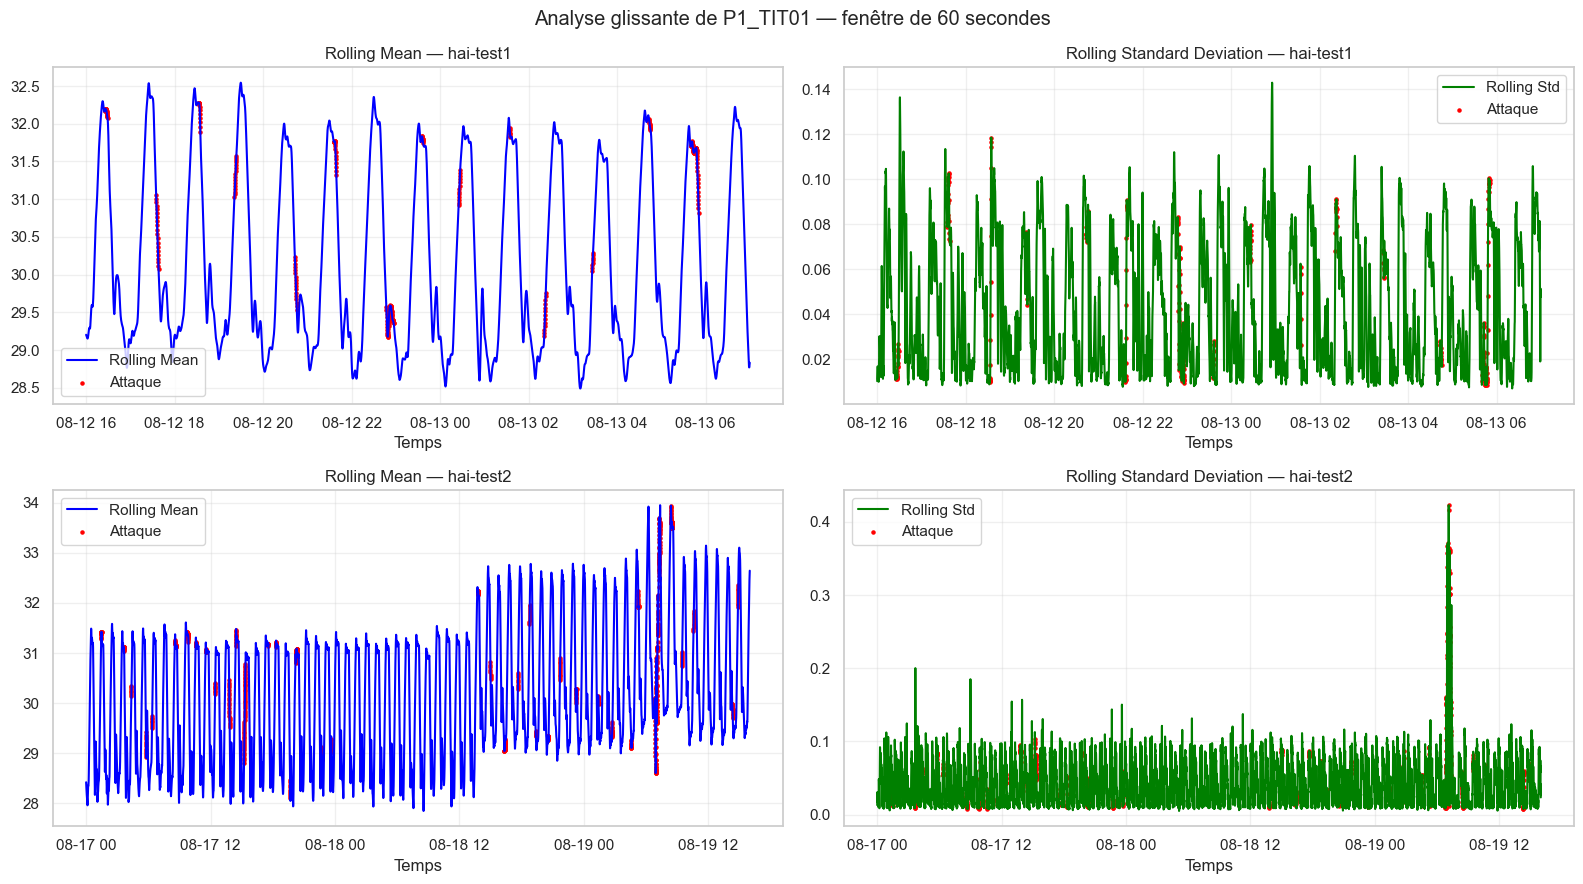

In [29]:
SENSOR = "P1_TIT01"
WINDOW = 60

fig, axes = plt.subplots(2, 2, figsize=(16, 9))

for i, segment in enumerate(["hai-test1", "hai-test2"]):
    data = SEGMENTS[segment].copy()

    # Calcul sur les données originales
    rolling_mean = data[SENSOR].rolling(
        window=WINDOW, min_periods=30, center=True
    ).mean()

    rolling_std = data[SENSOR].rolling(
        window=WINDOW, min_periods=30, center=True
    ).std()

    # Alléger uniquement l'affichage
    idx = np.arange(0, len(data), 10)

    # Moyenne glissante
    axes[i, 0].plot(
        data["timestamp"].iloc[idx],
        rolling_mean.iloc[idx],
        color="blue",
        label="Rolling Mean"
    )

    # Écart-type glissant
    axes[i, 1].plot(
        data["timestamp"].iloc[idx],
        rolling_std.iloc[idx],
        color="green",
        label="Rolling Std"
    )

    # Marquer les périodes d'attaque
    attack_idx = idx[data["label"].iloc[idx].to_numpy() == 1]

    axes[i, 0].scatter(
        data["timestamp"].iloc[attack_idx],
        rolling_mean.iloc[attack_idx],
        color="red", s=5, label="Attaque"
    )

    axes[i, 1].scatter(
        data["timestamp"].iloc[attack_idx],
        rolling_std.iloc[attack_idx],
        color="red", s=5, label="Attaque"
    )

    axes[i, 0].set_title(f"Rolling Mean — {segment}")
    axes[i, 1].set_title(f"Rolling Standard Deviation — {segment}")

    for ax in axes[i]:
        ax.set_xlabel("Temps")
        ax.legend()
        ax.grid(alpha=0.3)

plt.suptitle(f"Analyse glissante de {SENSOR} — fenêtre de 60 secondes")
plt.tight_layout()
plt.show()

In [30]:
for segment in ["hai-test1", "hai-test2"]:
    data = SEGMENTS[segment]
    mean_roll = data["P1_TIT01"].rolling(60, min_periods=30).mean()
    std_roll = data["P1_TIT01"].rolling(60, min_periods=30).std()

    print(f"\n--- {segment} ---")
    print("Moyenne du Rolling Mean :", round(mean_roll.mean(), 4))
    print("Moyenne du Rolling Std  :", round(std_roll.mean(), 4))
    print("Maximum du Rolling Std  :", round(std_roll.max(), 4))


--- hai-test1 ---
Moyenne du Rolling Mean : 30.1702
Moyenne du Rolling Std  : 0.0436
Maximum du Rolling Std  : 0.1434

--- hai-test2 ---
Moyenne du Rolling Mean : 30.1422
Moyenne du Rolling Std  : 0.0459
Maximum du Rolling Std  : 0.4281


**Interprétation :**

L'analyse des moyennes glissantes montre une stabilité globale de la température `P1_TIT01` dans les deux fichiers de test. Cependant, l'écart-type glissant maximal est nettement plus élevé dans `hai-test2` (0,4281) que dans `hai-test1` (0,1434). Cela indique que le deuxième segment contient des périodes de fluctuations plus importantes. Ces variations peuvent correspondre à des perturbations du processus industriel.

Analyse de l'autocorrélation (ACF)
1. Objectif
L'ACF (Autocorrelation Function) permet d'étudier la relation entre les valeurs actuelles d'un capteur et ses valeurs précédentes.

Elle permet notamment de :
- Identifier si les mesures dépendent des observations précédentes.
- Détecter des comportements périodiques.
- Observer si les dépendances temporelles changent entre les deux fichiers de test.

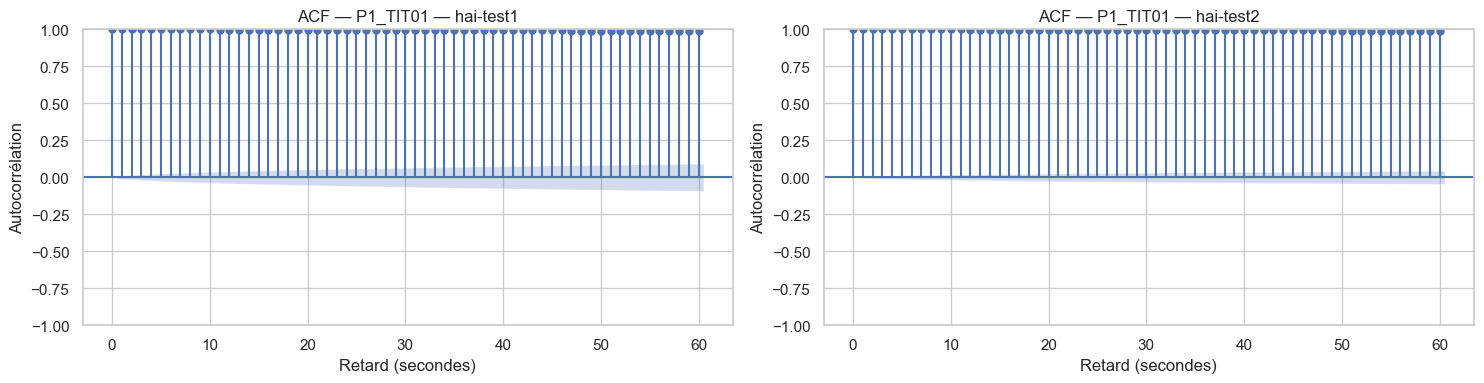

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

for i, segment in enumerate(["hai-test1", "hai-test2"]):
    signal = SEGMENTS[segment]["P1_TIT01"].dropna()

    plot_acf(
        signal,
        lags=60,
        ax=axes[i],
        title=f"ACF — P1_TIT01 — {segment}"
    )

    axes[i].set_xlabel("Retard (secondes)")
    axes[i].set_ylabel("Autocorrélation")

plt.tight_layout()
plt.show()

In [32]:
from statsmodels.tsa.stattools import acf

for segment in ["hai-test1", "hai-test2"]:
    signal = SEGMENTS[segment]["P1_TIT01"].dropna()

    valeurs_acf = acf(signal, nlags=60, fft=True)

    print(f"\n--- {segment} ---")
    print("ACF à 1 seconde :", round(valeurs_acf[1], 4))
    print("ACF à 10 secondes :", round(valeurs_acf[10], 4))
    print("ACF à 30 secondes :", round(valeurs_acf[30], 4))
    print("ACF à 60 secondes :", round(valeurs_acf[60], 4))


--- hai-test1 ---
ACF à 1 seconde : 0.9999
ACF à 10 secondes : 0.9995
ACF à 30 secondes : 0.9968
ACF à 60 secondes : 0.9884

--- hai-test2 ---
ACF à 1 seconde : 0.9999
ACF à 10 secondes : 0.9995
ACF à 30 secondes : 0.997
ACF à 60 secondes : 0.9891


**Interprétation :**

L'analyse ACF de `P1_TIT01` révèle une très forte autocorrélation dans les deux fichiers de test. Les valeurs diminuent progressivement avec le retard, tout en restant supérieures à 0,98 après 60 secondes. Cela indique une forte dépendance temporelle et une évolution relativement continue du signal. Les comportements de `hai-test1` et `hai-test2` sont très similaires selon cet indicateur.

Conclusion de la section 6.5
L'analyse ACF confirme que les mesures de température présentent une forte dépendance temporelle. Cette propriété doit être prise en compte lors de la construction des modèles de détection d'attaques.

6.6 — Lag Analysis : analyse des décalages temporels entre capteurs

Cette analyse permet d'étudier si les variations d'un capteur sont liées aux variations d'un autre capteur, avec un éventuel décalage dans le temps.

Calcul de la corrélation avec décalage

hai-test1 : corrélation maximale = -0.6820, décalage = 0 secondes
hai-test2 : corrélation maximale = -0.6838, décalage = 0 secondes


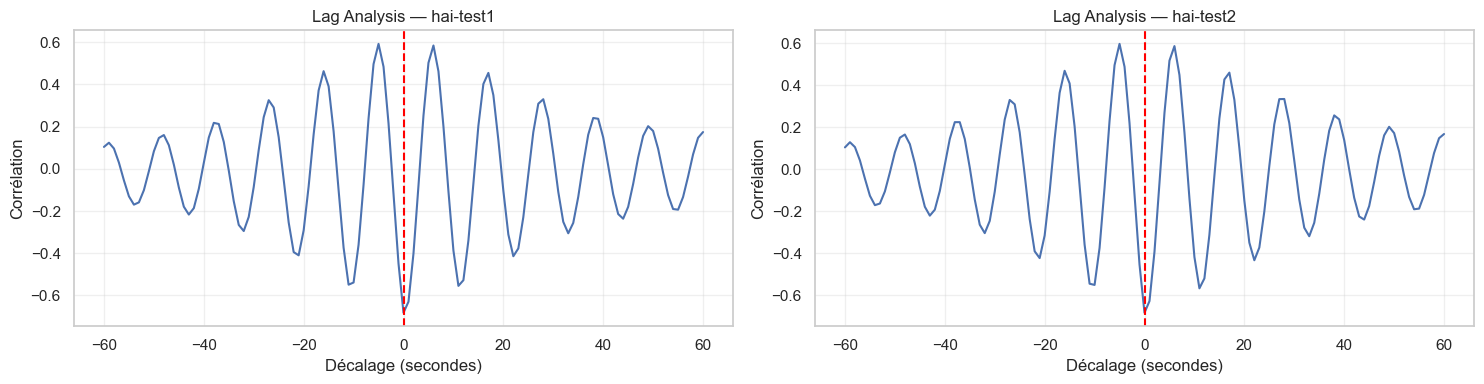

In [34]:
MAX_LAG = 60

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

for i, segment in enumerate(["hai-test1", "hai-test2"]):
    data = SEGMENTS[segment]

    valve = data["P1_FCV02Z"].diff().to_numpy()
    pressure = data["P1_PIT02"].diff().to_numpy()

    lags = range(-MAX_LAG, MAX_LAG + 1)
    correlations = []

    for lag in lags:
        if lag > 0:
            x, y = valve[:-lag], pressure[lag:]
        elif lag < 0:
            x, y = valve[-lag:], pressure[:lag]
        else:
            x, y = valve, pressure

        valid = np.isfinite(x) & np.isfinite(y)
        corr = np.corrcoef(x[valid], y[valid])[0, 1]
        correlations.append(corr)

    axes[i].plot(list(lags), correlations)
    axes[i].axvline(0, color="red", linestyle="--")
    axes[i].set_title(f"Lag Analysis — {segment}")
    axes[i].set_xlabel("Décalage (secondes)")
    axes[i].set_ylabel("Corrélation")
    axes[i].grid(alpha=0.3)

    best_idx = np.nanargmax(np.abs(correlations))
    print(
        f"{segment} : corrélation maximale = "
        f"{correlations[best_idx]:.4f}, "
        f"décalage = {list(lags)[best_idx]} secondes"
    )

plt.tight_layout()
plt.show()

**Interprétation :**

L'analyse des décalages temporels révèle une corrélation négative entre les variations de la vanne `P1_FCV02Z` et celles de la pression `P1_PIT02`, avec des coefficients de -0,6820 pour `hai-test1` et -0,6838 pour `hai-test2`. Le décalage optimal est de 0 seconde dans les deux cas, ce qui indique une évolution simultanée des variations des deux variables. Cette relation reste similaire dans les deux segments.

**Change Point Detection (détection des points de changement)**

La détection des points de changement (Change Point Detection) permet d'identifier les instants où le comportement d'un signal change de manière significative.

Nous cherchons notamment à repérer :
- Un changement de moyenne du signal.
- Une modification de sa variabilité.
- Une rupture dans son comportement habituel.

hai-test1 : 30 points de changement détectés
hai-test2 : 127 points de changement détectés


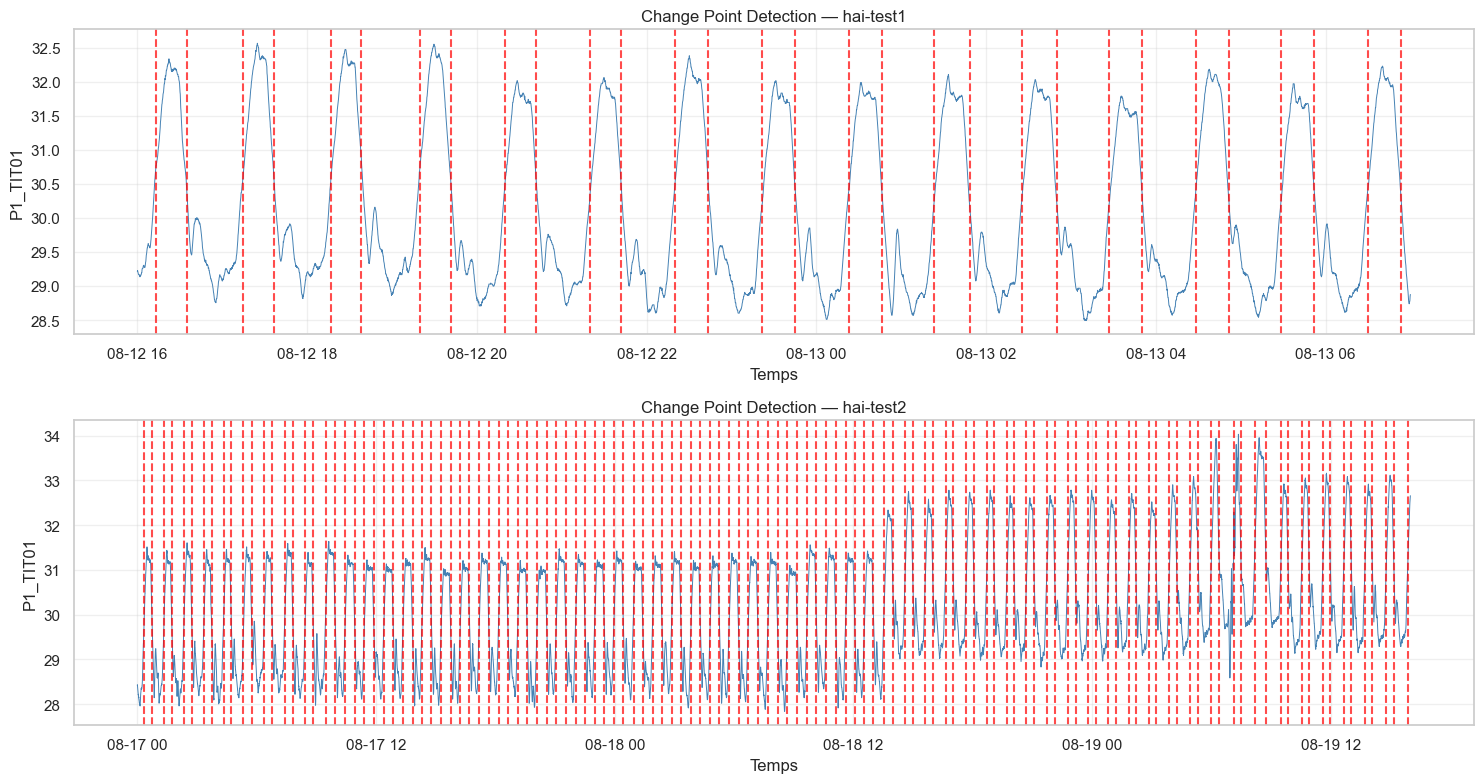

In [35]:
import ruptures as rpt

SENSOR = "P1_TIT01"

fig, axes = plt.subplots(2, 1, figsize=(15, 8))

for i, segment in enumerate(["hai-test1", "hai-test2"]):
    data = SEGMENTS[segment]

    # Échantillonnage toutes les 10 secondes
    sample = data.iloc[::10].copy()
    signal = sample[SENSOR].to_numpy()

    # Standardisation du signal
    signal_std = (signal - signal.mean()) / signal.std()

    # Détection des points de changement
    algo = rpt.Pelt(model="l2", min_size=30, jump=10)
    algo.fit(signal_std)

    breakpoints = algo.predict(pen=5 * np.log(len(signal_std)))

    # Affichage
    axes[i].plot(
        sample["timestamp"], signal,
        color="steelblue", linewidth=0.7
    )

    for bp in breakpoints[:-1]:
        axes[i].axvline(
            sample["timestamp"].iloc[bp],
            color="red", linestyle="--", alpha=0.7
        )

    axes[i].set_title(f"Change Point Detection — {segment}")
    axes[i].set_xlabel("Temps")
    axes[i].set_ylabel(SENSOR)
    axes[i].grid(alpha=0.3)

    print(f"{segment} : {len(breakpoints) - 1} points de changement détectés")

plt.tight_layout()
plt.show()

**Interprétation :**

La détection des points de changement avec l'algorithme PELT identifie 30 ruptures dans `hai-test1` contre 127 dans `hai-test2`. Le deuxième segment présente donc davantage de changements dans le comportement temporel de la température `P1_TIT01`. Ce résultat suggère une dynamique plus variable dans `hai-test2`, sans permettre d'attribuer directement ces ruptures aux attaques.

**Analyse avant, pendant et après les attaques**

In [36]:
for segment in ["hai-test1", "hai-test2"]:
    data = SEGMENTS[segment]
    print(
        segment,
        "| Nombre de lignes :", len(data),
        "| Observations d'attaque :", int(data["label"].sum())
    )

hai-test1 | Nombre de lignes : 54000 | Observations d'attaque : 2981
hai-test2 | Nombre de lignes : 230400 | Observations d'attaque : 8403


In [37]:
results = []

for segment in ["hai-test1", "hai-test2"]:
    data = SEGMENTS[segment].reset_index(drop=True)
    labels = data["label"].to_numpy()
    signal = data["P1_TIT01"].to_numpy()

    attack_positions = np.where(labels == 1)[0]

    # Identifier les épisodes d'attaque
    splits = np.where(np.diff(attack_positions) > 1)[0] + 1
    episodes = np.split(attack_positions, splits)

    before_idx, after_idx = set(), set()

    for episode in episodes:
        start, end = episode[0], episode[-1]

        # 60 secondes avant l'attaque
        before_idx.update(
            i for i in range(max(0, start - 60), start)
            if labels[i] == 0
        )

        # 60 secondes après l'attaque
        after_idx.update(
            i for i in range(end + 1, min(len(data), end + 61))
            if labels[i] == 0
        )

    groups = {
        "Avant": signal[sorted(before_idx)],
        "Pendant": signal[attack_positions],
        "Après": signal[sorted(after_idx)]
    }

    for period, values in groups.items():
        results.append({
            "Segment": segment,
            "Période": period,
            "Nombre_observations": len(values),
            "Moyenne": np.mean(values),
            "Écart_type": np.std(values)
        })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Segment,Période,Nombre_observations,Moyenne,Écart_type
0,hai-test1,Avant,840,31.1297,0.9981
1,hai-test1,Pendant,2981,30.9271,1.0478
2,hai-test1,Après,840,30.9286,0.9436
3,hai-test2,Avant,2280,30.4842,1.1279
4,hai-test2,Pendant,8403,30.8093,1.3326
5,hai-test2,Après,2280,30.6617,1.2688


**Interprétation :**

L'analyse avant, pendant et après les attaques montre des variations du comportement de la température `P1_TIT01`. Dans `hai-test1`, la moyenne diminue légèrement pendant les attaques, tandis que dans `hai-test2`, elle augmente. L'écart-type est plus élevé pendant les attaques dans les deux segments, indiquant une variabilité accrue du signal. Après les attaques, le comportement ne revient pas nécessairement immédiatement à son état initial. Ces observations montrent que les périodes d'attaque peuvent être associées à des perturbations du processus industriel.

**Conclusion de la partie 6 :**

L'analyse temporelle du dataset HAI 23.05 a permis d'étudier l'évolution des variables industrielles, leur stabilité, leurs dépendances temporelles et leurs changements de comportement. Les analyses Rolling Mean et Rolling Standard Deviation ont révélé des périodes de variabilité plus importante, notamment dans `hai-test2`. L'analyse ACF a confirmé une forte dépendance temporelle des mesures. La Lag Analysis a montré une corrélation négative entre la position de la vanne et la pression. Enfin, la détection des points de changement et la comparaison avant, pendant et après les attaques ont mis en évidence des différences de comportement entre les deux segments.

Ces résultats montrent l'intérêt de l'analyse temporelle pour comprendre le fonctionnement du système industriel et préparer les étapes suivantes de détection des anomalies et des attaques.